# Failure validation

How often reported failures reproduce, and which rule should call them real.

The live cells are small and take a few minutes on a laptop CPU. Campaign-scale numbers are read from `results/v2/summary.json`. Everything here measures injected noise in one simple simulator setup, so none of it says anything about a real vehicle.

**Matching assessment**

- [Failure validation](https://niharvaghela1995.github.io/masters-thesis/assessments/s07_failure_validation.html)

In [1]:
import json, sys, tempfile, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from stp import runner, scenario as S
from stp.v2.config import CANDIDATES, LEVELS, cfg_for
from stp.v2 import rules as RL
SPACE = CANDIDATES["A"]
SUMMARY = json.load(open(ROOT / "results/v2/summary.json"))
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
BLUE, ORANGE = "#2a78d6", "#eb6834"
def along(speeds, k1=0.012, k2=-0.004, gust=0.8):
    return [S.Params(float(v), k1, k2, gust) for v in speeds]
def reruns(p, n, level="medium", base=0):
    return [runner.run(p, base + i, LEVELS[level]) for i in range(n)]


## S07-P01: flakiness-aware validation

Reported failures against the base rate, from the saved campaign. A reported failure that reproduces no more often than a random run fails carries no information about its scenario.

In [2]:
for l in ("low", "medium", "high"):
    s = SUMMARY[l]["search"]; print(l, "base rate %.3f, mean reproduction %.3f, partly reproducing %.3f, dispersion %.1f" % (s["base_rate"]["est"], s["rate_all"]["est"], s["shares"]["partly"], s["heterogeneity"]["dispersion"]))
V1 = json.load(open(ROOT / "results/diagnostics.json"))
print("first campaign dispersion:", {l: round(V1[l]["heterogeneity"]["dispersion"], 2) for l in ("medium", "high")})

low base rate 0.220, mean reproduction 0.992, partly reproducing 0.023, dispersion 10.2
medium base rate 0.233, mean reproduction 0.972, partly reproducing 0.058, dispersion 12.5
high base rate 0.290, mean reproduction 0.947, partly reproducing 0.125, dispersion 10.1
first campaign dispersion: {'medium': 1.09, 'high': 1.0}


## S07-P02: replication budgets and noise-aware verdicts

First the exact behaviour of each rule, which needs no simulation.

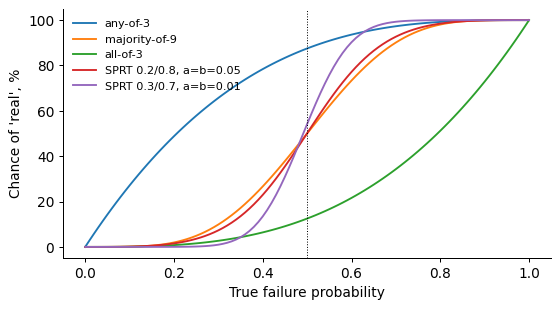

SPRT 0.3/0.7, a=b=0.05 chance of real at p = 0.2, 0.3, 0.4, 0.6, 0.7, 0.8: [0.004, 0.033, 0.175, 0.835, 0.967, 0.996] reruns at 0.5: 15.3
SPRT 0.2/0.8, a=b=0.05 chance of real at p = 0.2, 0.3, 0.4, 0.6, 0.7, 0.8: [0.015, 0.073, 0.229, 0.772, 0.927, 0.985] reruns at 0.5: 9.0
SPRT 0.4/0.6, a=b=0.05 chance of real at p = 0.2, 0.3, 0.4, 0.6, 0.7, 0.8: [0.0, 0.007, 0.129, 0.921, 0.997, 1.0] reruns at 0.5: 33.6
SPRT 0.3/0.7, a=b=0.01 chance of real at p = 0.2, 0.3, 0.4, 0.6, 0.7, 0.8: [0.0, 0.01, 0.134, 0.902, 0.993, 1.0] reruns at 0.5: 26.7


In [3]:
g = np.linspace(0, 1, 101); plt.figure(figsize=(7, 3.6))
for r in RL.shortlist(.5):
    if r.name in ("any-of-3", "all-of-3", "majority-of-9", "SPRT 0.2/0.8, a=b=0.05", "SPRT 0.3/0.7, a=b=0.01"):
        plt.plot(g, [100 * r.exact(float(q))[0] for q in g], label=r.name)
plt.axvline(.5, color="k", lw=.8, ls=":"); plt.xlabel("True failure probability"); plt.ylabel("Chance of 'real', %"); plt.legend(frameon=False, fontsize=9); plt.show()
for r in RL.shortlist(.5):
    if r.name.startswith("SPRT"): print(r.name, "chance of real at p = 0.2, 0.3, 0.4, 0.6, 0.7, 0.8:", [round(r.exact(q)[0], 3) for q in (.2, .3, .4, .6, .7, .8)], "reruns at 0.5:", round(r.exact(.5)[1], 1))

A miniature of the campaign's scoring: 8 scenarios on a line through the limit, 100 truth reruns and, on separate seeds, 40 rule reruns each.

In [4]:
t = time.time(); rows = []
for p in along(np.linspace(19, 24, 8)):
    truth = np.mean([r["failed"] for r in reruns(p, 100, "high", 10000)])
    seq = np.array([r["failed"] for r in reruns(p, 40, "high", 20000)], bool); rows.append((p.speed, truth, seq))
print(f"{time.time() - t:.0f} s")
names = ("any-of-3", "all-of-3", "majority-of-9", "SPRT 0.2/0.8, a=b=0.05")
R = {r.name: r for r in RL.shortlist(.5)}
print("speed  truth  " + "  ".join(names))
for v, q, s in rows: print(f"{v:5.1f}  {q:.2f}   " + "  ".join(("real" if R[n].apply(s)[0] else "no  ") + f"({R[n].apply(s)[1]})" for n in names))

58 s
speed  truth  any-of-3  all-of-3  majority-of-9  SPRT 0.2/0.8, a=b=0.05
 19.0  0.14   no  (3)  no  (3)  no  (9)  no  (3)
 19.7  0.18   real(3)  no  (3)  no  (9)  no  (9)
 20.4  0.39   real(3)  no  (3)  no  (9)  no  (11)
 21.1  0.54   real(3)  no  (3)  real(9)  real(17)
 21.9  0.63   real(3)  no  (3)  real(9)  real(5)
 22.6  0.92   real(3)  real(3)  real(9)  real(3)
 23.3  0.97   real(3)  real(3)  real(9)  real(3)
 24.0  1.00   real(3)  real(3)  real(9)  real(3)


The saved scores, on the full ground-truth set: errors on scenarios at least 0.1 from the 0.5 threshold.

In [5]:
show = ("any-of-3", "all-of-3", "majority-of-9", "SPRT 0.2/0.8, a=b=0.05", "SPRT 0.3/0.7, a=b=0.01")
for l in ("low", "medium", "high"):
    Q = SUMMARY[l]["truth"]["scores"]["0.5"]
    print(l, "| planned pick:", Q["recommended"]["rule"], "| exact-score pick:", Q["recommended_exact"]["rule"])
    for n in show:
        d = Q["rules"][n]["decidable"]; print(f"   {n:26s} false real {100 * d['false_real']['est']:5.1f}%  missed {100 * d['missed']['est']:5.1f}%  reruns {Q['rules'][n]['all']['reruns']['est']:.1f}")

low | planned pick: SPRT 0.3/0.7, a=b=0.01 | exact-score pick: SPRT 0.2/0.8, a=b=0.05
   any-of-3                   false real  37.8%  missed   4.8%  reruns 3.0
   all-of-3                   false real   2.3%  missed  20.9%  reruns 3.0
   majority-of-9              false real   4.6%  missed   7.2%  reruns 9.0
   SPRT 0.2/0.8, a=b=0.05     false real   4.6%  missed   7.2%  reruns 5.3
   SPRT 0.3/0.7, a=b=0.01     false real   2.3%  missed   0.0%  reruns 12.7
medium | planned pick: SPRT 0.2/0.8, a=b=0.05 | exact-score pick: SPRT 0.2/0.8, a=b=0.05
   any-of-3                   false real  34.0%  missed   2.5%  reruns 3.0
   all-of-3                   false real   0.0%  missed  27.2%  reruns 3.0
   majority-of-9              false real   2.1%  missed   4.9%  reruns 9.0
   SPRT 0.2/0.8, a=b=0.05     false real   3.1%  missed   3.7%  reruns 4.9
   SPRT 0.3/0.7, a=b=0.01     false real   0.0%  missed   0.0%  reruns 11.2
high | planned pick: majority-of-5 | exact-score pick: SPRT 0.2/0.8, a=b=